# Análise de e-commerce com SQL: vendas, logística, retenção e clientes da Olist

# Contents <a id='back'></a>

* [Introdução](#intro)
* [Etapa 1. Criando o banco de dados](#database)
* [Etapa 2. Qualidade dos dados](#quality)
* [Etapa 3. Visão geral do negócio](#overview)
* [Etapa 4. Evolução das vendas](#trend)
* [Etapa 5. Categorias: onde está a receita](#categories)
* [Etapa 6. Geografia e frete](#geography)
* [Etapa 7. Logística e satisfação dos clientes](#delivery)
* [Etapa 8. Retenção: os clientes voltam a comprar?](#retention)
* [Etapa 9. Desempenho dos vendedores](#sellers)
* [Etapa 10. Pagamentos e parcelamento](#payments)
* [Etapa 11. Segmentação RFM com SQL](#rfm)
* [Conclusão geral](#end)

## Introdução <a id='intro'></a>

A **Olist** é uma plataforma brasileira que conecta pequenos e médios lojistas aos grandes marketplaces. Neste projeto, analiso cerca de **100 mil pedidos** feitos entre 2016 e 2018, com **SQL**, para responder às perguntas que a liderança de um e-commerce faz no dia a dia.

### Perguntas de negócio
1. Como as vendas evoluíram e qual é o tamanho do negócio?
2. Quais categorias concentram a receita?
3. Em quais estados o frete pesa mais?
4. **Atrasos na entrega afetam a satisfação dos clientes?**
5. **Os clientes voltam a comprar?**
6. Quais vendedores se destacam, e quais preocupam?
7. Como os clientes pagam?
8. Como segmentar a base de clientes para ações de marketing?

### Por que SQL?
Em empresas, os dados ficam em **bancos de dados relacionais**, e o SQL é a forma de consultá-los. Por isso, carrego as tabelas em um banco **SQLite** e faço toda a análise com consultas SQL, usando **JOINs, CTEs (WITH), funções de janela (window functions) e CASE**. O Python entra só para criar o banco e fazer os gráficos.

### Descrição dos dados

Base pública *Brazilian E-Commerce Public Dataset by Olist*, com dados reais e anonimizados, licença CC BY-NC-SA 4.0. São 8 tabelas relacionadas:

| Tabela no banco | Conteúdo | Liga-se por |
|---|---|---|
| `pedidos` | Status e datas de cada pedido (compra, entrega, prazo estimado) | `order_id`, `customer_id` |
| `itens` | Produtos de cada pedido, com preço e frete | `order_id`, `product_id`, `seller_id` |
| `clientes` | Cidade e estado do cliente | `customer_id`, `customer_unique_id` |
| `pagamentos` | Meio de pagamento, parcelas e valor | `order_id` |
| `avaliacoes` | Nota de 1 a 5 dada pelo cliente | `order_id` |
| `produtos` | Categoria e dimensões dos produtos | `product_id` |
| `vendedores` | Cidade e estado do vendedor | `seller_id` |
| `categorias` | Tradução das categorias para o inglês | `product_category_name` |

Um detalhe importante: cada pedido gera um `customer_id` novo. Para identificar a **mesma pessoa** em pedidos diferentes, é preciso usar o `customer_unique_id`.

[Voltar ao Índice](#back)

## Etapa 1. Criando o banco de dados <a id='database'></a>

Se estiver usando o Google Colab ou outro Jupyter online, as bibliotecas abaixo já costumam estar instaladas.

In [1]:
# Instalação das bibliotecas (só é necessário se alguma não estiver instalada)
# %pip install pandas matplotlib seaborn

In [2]:
# Importa as bibliotecas necessárias
import os  # Utilizada para verificar arquivos e pastas
import sqlite3  # Banco de dados SQL que já vem com o Python
import urllib.request  # Utilizada para baixar os dados
import zipfile  # Utilizada para descompactar os dados

import pandas as pd  # Utilizada para ler os arquivos e mostrar os resultados das consultas
import matplotlib.pyplot as plt  # Utilizada para a construção de gráficos
import matplotlib.ticker as mtick  # Utilizada para formatar os eixos dos gráficos
import seaborn as sns  # Utilizada para gráficos estatísticos

# Padroniza a aparência dos gráficos
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, LARANJA, CINZA, VERMELHO = "#1f4e79", "#e07b00", "#9aa5b1", "#c0392b"
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")  # Duas casas decimais nas tabelas

In [3]:
# Baixa e descompacta os dados, se ainda não estiverem na pasta
ARQUIVO_ZIP = "olist.zip"
URL_GITHUB = "https://raw.githubusercontent.com/gabrieldeoliver1/Projetos/main/Projeto_20/olist.zip"
if not os.path.exists(ARQUIVO_ZIP):
    print("Baixando os dados do GitHub (cerca de 29 MB)...")
    urllib.request.urlretrieve(URL_GITHUB, ARQUIVO_ZIP)
with zipfile.ZipFile(ARQUIVO_ZIP) as z:
    z.extractall("dados_olist")

# Nome de cada tabela no banco e o arquivo correspondente
TABELAS = {
    "pedidos": "olist_orders_dataset.csv",
    "itens": "olist_order_items_dataset.csv",
    "clientes": "olist_customers_dataset.csv",
    "pagamentos": "olist_order_payments_dataset.csv",
    "avaliacoes": "olist_order_reviews_dataset.csv",
    "produtos": "olist_products_dataset.csv",
    "vendedores": "olist_sellers_dataset.csv",
    "categorias": "product_category_name_translation.csv",
}

# Cria o banco SQLite e carrega cada arquivo como uma tabela
conexao = sqlite3.connect("olist.db")
for tabela, arquivo in TABELAS.items():
    pd.read_csv(f"dados_olist/{arquivo}").to_sql(tabela, conexao, if_exists="replace", index=False)
print("Banco de dados criado com", len(TABELAS), "tabelas.")

Banco de dados criado com 8 tabelas.


Para não repetir código, crio uma função que recebe uma consulta SQL e devolve o resultado como tabela.

In [4]:
def consulta(sql):
    """Executa uma consulta SQL no banco e devolve o resultado como DataFrame."""
    return pd.read_sql_query(sql, conexao)


# Primeira consulta: quantas linhas tem cada tabela?
consulta("""
SELECT 'pedidos' AS tabela, COUNT(*) AS linhas FROM pedidos
UNION ALL SELECT 'itens', COUNT(*) FROM itens
UNION ALL SELECT 'clientes', COUNT(*) FROM clientes
UNION ALL SELECT 'pagamentos', COUNT(*) FROM pagamentos
UNION ALL SELECT 'avaliacoes', COUNT(*) FROM avaliacoes
UNION ALL SELECT 'produtos', COUNT(*) FROM produtos
UNION ALL SELECT 'vendedores', COUNT(*) FROM vendedores
UNION ALL SELECT 'categorias', COUNT(*) FROM categorias
""")

,tabela,linhas
0,pedidos,99441
1,itens,112650
2,clientes,99441
3,pagamentos,103886
4,avaliacoes,99224
5,produtos,32951
6,vendedores,3095
7,categorias,71


[Voltar ao Índice](#back)

## Etapa 2. Qualidade dos dados <a id='quality'></a>

Antes de analisar, verifico o status dos pedidos, o período coberto e possíveis duplicidades.

In [5]:
# Status dos pedidos e participação de cada um
consulta("""
SELECT
    order_status AS status,
    COUNT(*) AS pedidos,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS percentual  -- Função de janela: total geral
FROM pedidos
GROUP BY order_status
ORDER BY pedidos DESC
""")

,status,pedidos,percentual
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [6]:
# Pedidos por mês: o período começa e termina com meses incompletos?
pedidos_mes = consulta("""
SELECT strftime('%Y-%m', order_purchase_timestamp) AS mes, COUNT(*) AS pedidos
FROM pedidos
GROUP BY mes
ORDER BY mes
""")
pd.concat([pedidos_mes.head(4), pedidos_mes.tail(4)])

,mes,pedidos
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
21,2018-07,6292
22,2018-08,6512
23,2018-09,16
24,2018-10,4


In [7]:
# Um pedido pode ter mais de uma avaliação? E entregas sem data registrada?
consulta("""
SELECT
    (SELECT COUNT(*) FROM (SELECT order_id FROM avaliacoes GROUP BY order_id HAVING COUNT(*) > 1))
        AS pedidos_com_mais_de_uma_avaliacao,
    (SELECT COUNT(*) FROM pedidos
     WHERE order_status = 'delivered' AND order_delivered_customer_date IS NULL)
        AS entregues_sem_data_de_entrega
""")

,pedidos_com_mais_de_uma_avaliacao,entregues_sem_data_de_entrega
0,547,8


### Decisões a partir da qualidade dos dados

- **97% dos pedidos foram entregues.** As análises de receita usam só os pedidos com status `delivered`, que são vendas concretizadas.
- **Os meses das pontas estão incompletos:** setembro a dezembro de 2016 têm poucos pedidos (início da operação), e setembro e outubro de 2018 também. Nas análises de evolução, uso de **janeiro de 2017 a agosto de 2018**.
- Alguns pedidos têm **mais de uma avaliação**. Para não contar o mesmo pedido duas vezes, uso a **nota média por pedido**.
- Poucos pedidos entregues não têm data de entrega; eles ficam de fora das análises de prazo.
- **Receita**, neste projeto, é a soma do preço dos produtos com o frete, a partir da tabela de itens.

[Voltar ao Índice](#back)

## Etapa 3. Visão geral do negócio <a id='overview'></a>

**Pergunta:** qual é o tamanho do negócio?

In [8]:
consulta("""
SELECT
    COUNT(DISTINCT p.order_id)                                       AS pedidos_entregues,
    COUNT(DISTINCT c.customer_unique_id)                             AS clientes_unicos,
    COUNT(DISTINCT i.seller_id)                                      AS vendedores,
    ROUND(SUM(i.price + i.freight_value), 2)                         AS receita_total,
    ROUND(SUM(i.price + i.freight_value) / COUNT(DISTINCT p.order_id), 2) AS ticket_medio,
    ROUND(100.0 * SUM(i.freight_value) / SUM(i.price), 1)            AS frete_percentual_do_preco
FROM pedidos AS p
JOIN itens AS i     ON i.order_id = p.order_id
JOIN clientes AS c  ON c.customer_id = p.customer_id
WHERE p.order_status = 'delivered'
""").T.rename(columns={0: "valor"})

,valor
pedidos_entregues,"96,478.00"
clientes_unicos,"93,358.00"
vendedores,"2,970.00"
receita_total,"15,419,773.75"
ticket_medio,159.83
frete_percentual_do_preco,16.60


### Conclusões

- Foram **96.478 pedidos entregues** para **93.358 clientes únicos**, por quase **3 mil vendedores**, somando **R\$ 15,4 milhões** de receita.
- O **ticket médio é de R\$ 159,83** por pedido.
- O **frete equivale a 16,6% do preço** dos produtos, um peso relevante na decisão de compra.

[Voltar ao Índice](#back)

## Etapa 4. Evolução das vendas <a id='trend'></a>

**Pergunta:** como as vendas evoluíram mês a mês?

Uso duas funções de janela:
- `LAG()` traz o valor do mês anterior, para calcular o **crescimento mensal**
- `AVG() OVER (ROWS BETWEEN 2 PRECEDING AND CURRENT ROW)` calcula a **média móvel de 3 meses**, que suaviza as oscilações

In [9]:
evolucao = consulta("""
WITH vendas_mes AS (
    -- Receita e pedidos de cada mês
    SELECT
        strftime('%Y-%m', p.order_purchase_timestamp) AS mes,
        COUNT(DISTINCT p.order_id) AS pedidos,
        SUM(i.price + i.freight_value) AS receita
    FROM pedidos AS p
    JOIN itens AS i ON i.order_id = p.order_id
    WHERE p.order_status = 'delivered'
      AND p.order_purchase_timestamp BETWEEN '2017-01-01' AND '2018-08-31 23:59:59'
    GROUP BY mes
)
SELECT
    mes,
    pedidos,
    ROUND(receita, 2) AS receita,
    ROUND(100.0 * (receita - LAG(receita) OVER (ORDER BY mes)) / LAG(receita) OVER (ORDER BY mes), 1)
        AS crescimento_mensal_pct,
    ROUND(AVG(receita) OVER (ORDER BY mes ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2)
        AS media_movel_3m
FROM vendas_mes
ORDER BY mes
""")
evolucao

,mes,pedidos,receita,crescimento_mensal_pct,media_movel_3m
0,2017-01,750,"127,482.37",NaN,"127,482.37"
1,2017-02,1653,"271,239.32",112.80,"199,360.85"
2,2017-03,2546,"414,330.95",52.80,"271,017.55"
3,2017-04,2303,"390,812.40",-5.70,"358,794.22"
4,2017-05,3546,"566,851.40",45.00,"457,331.58"
5,2017-06,3135,"490,050.37",-13.50,"482,571.39"
6,2017-07,3872,"566,299.08",15.60,"541,066.95"
7,2017-08,4193,"645,832.36",14.00,"567,393.94"
8,2017-09,4150,"701,077.49",8.60,"637,736.31"
9,2017-10,4478,"751,117.01",7.10,"699,342.29"


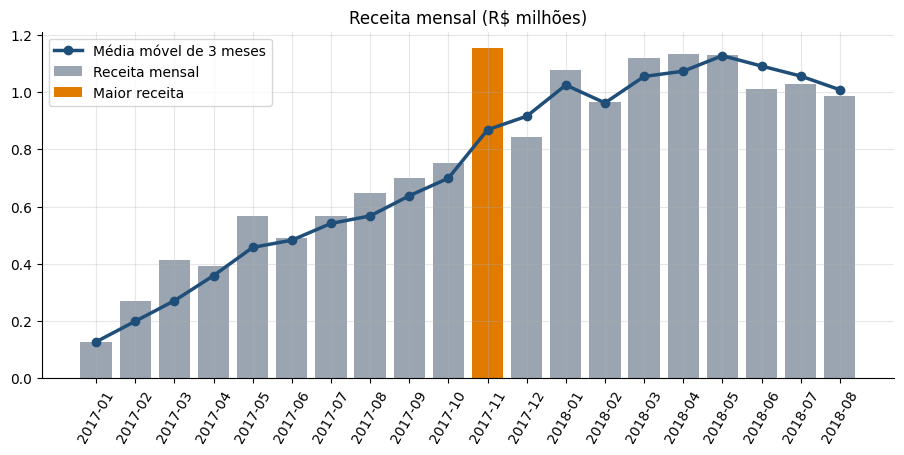

 ano  receita_jan_ago
2017     3,472,898.25
2018     8,451,584.77
Crescimento de janeiro a agosto: 143%


In [10]:
# Gráfico da receita mensal com a média móvel
fig, ax = plt.subplots()
ax.bar(evolucao["mes"], evolucao["receita"] / 1e6, color=CINZA, label="Receita mensal")
ax.plot(evolucao["mes"], evolucao["media_movel_3m"] / 1e6, color=AZUL, lw=2.5, marker="o", label="Média móvel de 3 meses")
destaque = evolucao["receita"].idxmax()  # Mês de maior receita
ax.bar(evolucao.loc[destaque, "mes"], evolucao.loc[destaque, "receita"] / 1e6, color=LARANJA, label="Maior receita")
ax.set_title("Receita mensal (R$ milhões)")
ax.tick_params(axis="x", rotation=60)
ax.legend()
plt.show()

# Comparação dos 8 primeiros meses de 2017 e de 2018
comparacao = consulta("""
SELECT strftime('%Y', p.order_purchase_timestamp) AS ano, ROUND(SUM(i.price + i.freight_value), 2) AS receita_jan_ago
FROM pedidos AS p JOIN itens AS i ON i.order_id = p.order_id
WHERE p.order_status = 'delivered' AND strftime('%m', p.order_purchase_timestamp) <= '08'
  AND strftime('%Y', p.order_purchase_timestamp) IN ('2017', '2018')
GROUP BY ano
""")
print(comparacao.to_string(index=False))
print(f"Crescimento de janeiro a agosto: {comparacao.receita_jan_ago.iloc[1] / comparacao.receita_jan_ago.iloc[0] - 1:.0%}")

### Conclusões

- O negócio **cresceu rápido em 2017**: a receita mensal saiu de R\$ 127 mil em janeiro para mais de R\$ 750 mil em outubro.
- O maior mês foi **novembro de 2017**, com R\$ 1,15 milhão e alta de 54% sobre outubro, efeito da **Black Friday**.
- Em 2018, a receita se estabilizou em um **patamar de R\$ 1,0 a 1,1 milhão por mês**. Mesmo assim, de janeiro a agosto, 2018 faturou **143% a mais** que o mesmo período de 2017.
- A estabilização em 2018 é um ponto de atenção para a liderança: o crescimento acelerado ficou para trás, e as próximas alavancas precisam vir de retenção e ticket médio.

[Voltar ao Índice](#back)

## Etapa 5. Categorias: onde está a receita <a id='categories'></a>

**Pergunta:** quais categorias concentram a receita? Poucas categorias respondem pela maior parte das vendas?

Para responder à segunda pergunta, calculo a **participação acumulada** com `SUM() OVER (ORDER BY ...)`, a base da **análise de Pareto**.

In [11]:
categorias = consulta("""
WITH receita_categoria AS (
    SELECT
        COALESCE(pr.product_category_name, 'sem_categoria') AS categoria,
        COUNT(DISTINCT i.order_id) AS pedidos,
        SUM(i.price) AS receita
    FROM itens AS i
    JOIN pedidos AS p  ON p.order_id = i.order_id
    LEFT JOIN produtos AS pr ON pr.product_id = i.product_id
    WHERE p.order_status = 'delivered'
    GROUP BY categoria
)
SELECT
    categoria,
    pedidos,
    ROUND(receita, 2) AS receita,
    ROUND(receita / pedidos, 2) AS ticket_medio,
    ROUND(100.0 * receita / SUM(receita) OVER (), 2) AS participacao_pct,
    ROUND(100.0 * SUM(receita) OVER (ORDER BY receita DESC) / SUM(receita) OVER (), 2) AS acumulado_pct,
    RANK() OVER (ORDER BY receita DESC) AS ranking
FROM receita_categoria
ORDER BY receita DESC
""")
print(f"Total de categorias: {len(categorias)}")
print(f"Categorias que somam 80% da receita: {(categorias['acumulado_pct'] <= 80).sum() + 1}")
categorias.head(10)

Total de categorias: 74
Categorias que somam 80% da receita: 18


,categoria,pedidos,receita,ticket_medio,participacao_pct,acumulado_pct,ranking
0,beleza_saude,8647,"1,233,131.72",142.61,9.33,9.33,1
1,relogios_presentes,5495,"1,166,176.98",212.23,8.82,18.15,2
2,cama_mesa_banho,9272,"1,023,434.76",110.38,7.74,25.89,3
3,esporte_lazer,7530,"954,852.55",126.81,7.22,33.11,4
4,informatica_acessorios,6530,"888,724.61",136.10,6.72,39.83,5
5,moveis_decoracao,6307,"711,927.69",112.88,5.38,45.22,6
6,utilidades_domesticas,5743,"615,628.69",107.20,4.66,49.87,7
7,cool_stuff,3559,"610,204.10",171.45,4.62,54.49,8
8,automotivo,3810,"578,966.65",151.96,4.38,58.87,9
9,brinquedos,3804,"471,286.48",123.89,3.56,62.43,10


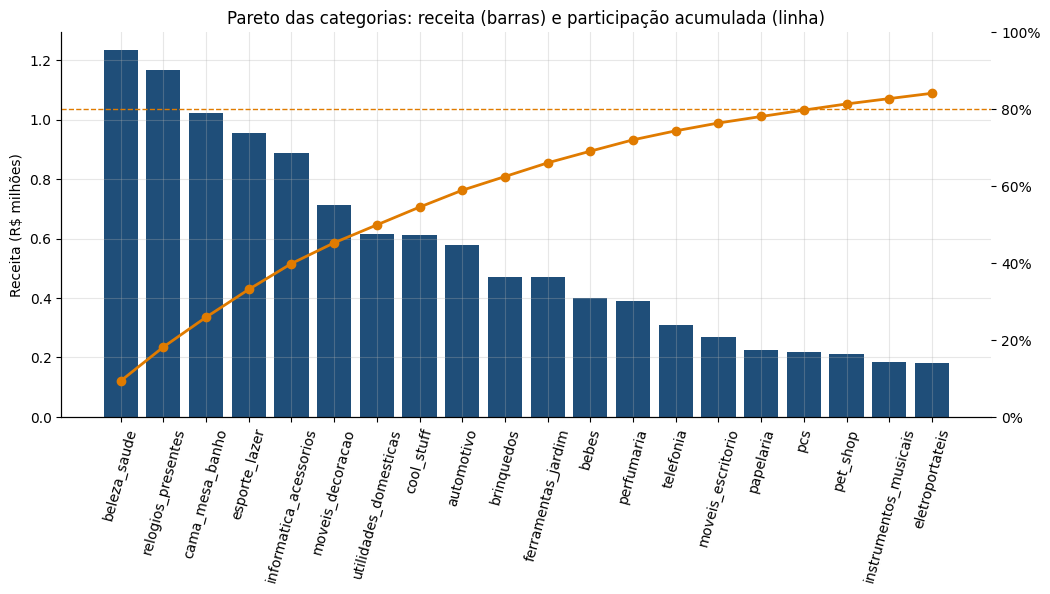

In [12]:
# Gráfico de Pareto das 20 maiores categorias
top = categorias.head(20)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(top["categoria"], top["receita"] / 1e6, color=AZUL)
ax.set_ylabel("Receita (R$ milhões)")
ax.tick_params(axis="x", rotation=75)
ax2 = ax.twinx()  # Segundo eixo para a participação acumulada
ax2.plot(top["categoria"], top["acumulado_pct"], color=LARANJA, marker="o", lw=2)
ax2.axhline(80, color=LARANJA, ls="--", lw=1)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylim(0, 100)
ax2.grid(False)
ax.set_title("Pareto das categorias: receita (barras) e participação acumulada (linha)")
plt.show()

### Conclusões

- Das 74 categorias, **18 respondem por 80% da receita**, um padrão típico de Pareto.
- **Beleza e saúde** lidera (9,3% da receita), seguida de **relógios e presentes** (8,8%) e **cama, mesa e banho** (7,7%).
- **Relógios e presentes** tem o maior ticket médio entre as líderes (R\$ 212), enquanto **cama, mesa e banho** tem o maior número de pedidos, mas ticket baixo (R\$ 110).
- Recomendação: concentrar esforços comerciais e de estoque nas 18 categorias principais, e usar as de alto volume e ticket baixo como porta de entrada para novos clientes.

[Voltar ao Índice](#back)

## Etapa 6. Geografia e frete <a id='geography'></a>

**Pergunta:** de onde vêm os clientes e em quais estados o frete pesa mais no bolso?

In [13]:
estados = consulta("""
SELECT
    c.customer_state AS uf,
    COUNT(DISTINCT p.order_id) AS pedidos,
    ROUND(100.0 * COUNT(DISTINCT p.order_id) / SUM(COUNT(DISTINCT p.order_id)) OVER (), 2) AS participacao_pct,
    ROUND(SUM(i.price) / COUNT(DISTINCT p.order_id), 2) AS ticket_medio_produtos,
    ROUND(SUM(i.freight_value) / COUNT(DISTINCT p.order_id), 2) AS frete_medio_por_pedido,
    ROUND(100.0 * SUM(i.freight_value) / SUM(i.price), 1) AS frete_pct_do_preco
FROM pedidos AS p
JOIN clientes AS c ON c.customer_id = p.customer_id
JOIN itens AS i    ON i.order_id = p.order_id
WHERE p.order_status = 'delivered'
GROUP BY uf
ORDER BY pedidos DESC
""")
estados.head(10)

,uf,pedidos,participacao_pct,ticket_medio_produtos,frete_medio_por_pedido,frete_pct_do_preco
0,SP,40501,41.98,125.12,17.33,13.90
1,RJ,12350,12.80,142.48,23.95,16.80
2,MG,11354,11.77,136.73,23.46,17.20
3,RS,5345,5.54,136.37,24.80,18.20
4,PR,4923,5.10,135.30,23.49,17.40
5,SC,3546,3.68,142.98,24.85,17.40
6,BA,3256,3.37,151.59,29.96,19.80
7,DF,2080,2.16,142.55,23.86,16.70
8,ES,1995,2.07,134.66,24.57,18.20
9,GO,1957,2.03,144.53,26.25,18.20


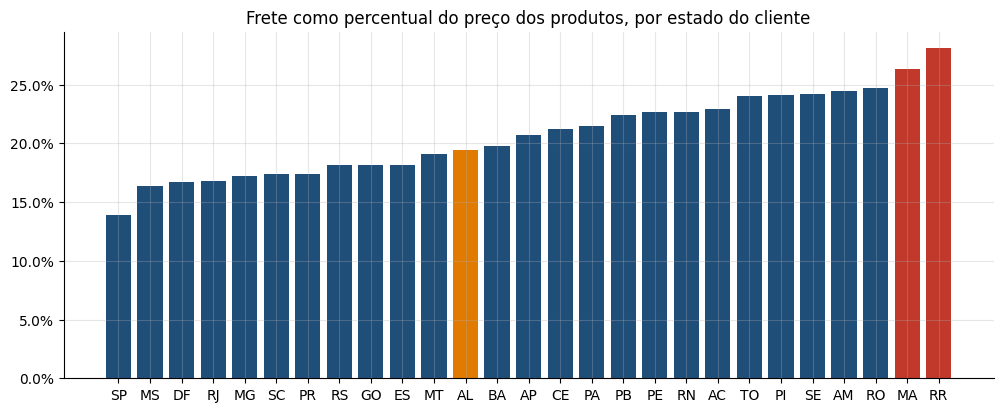

Os 3 estados do Sudeste (SP, RJ, MG) concentram 66.5% dos pedidos
uf  frete_medio_por_pedido  frete_pct_do_preco
SP                   17.33               13.90
AL                   38.58               19.40
RR                   48.34               28.10


In [14]:
# Frete como % do preço em cada estado
ordenado = estados.sort_values("frete_pct_do_preco")
cores = [LARANJA if uf == "AL" else (VERMELHO if v > 25 else AZUL) for uf, v in zip(ordenado.uf, ordenado.frete_pct_do_preco)]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(ordenado["uf"], ordenado["frete_pct_do_preco"], color=cores)
ax.set_title("Frete como percentual do preço dos produtos, por estado do cliente")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.show()
print(f"Os 3 estados do Sudeste (SP, RJ, MG) concentram {estados.query('uf in [\"SP\", \"RJ\", \"MG\"]').participacao_pct.sum():.1f}% dos pedidos")
print(estados[estados.uf.isin(["SP", "AL", "RR"])][["uf", "frete_medio_por_pedido", "frete_pct_do_preco"]].to_string(index=False))

### Conclusões

- **SP, RJ e MG concentram 66,5% dos pedidos**; só São Paulo responde por 42%.
- O **frete pesa muito mais longe do Sudeste**: em SP, equivale a 13,9% do preço; em Roraima, chega a 28,1%. Em **Alagoas**, o frete médio por pedido é de R\$ 38,58, mais que o dobro do de São Paulo (R\$ 17,33).
- Como os vendedores estão concentrados no Sudeste, o frete é uma **barreira de crescimento** no Norte e no Nordeste. Parcerias logísticas regionais ou vendedores locais podem destravar essas regiões.

[Voltar ao Índice](#back)

## Etapa 7. Logística e satisfação dos clientes <a id='delivery'></a>

**Pergunta:** quanto tempo as entregas levam, quantas atrasam e **o atraso afeta a nota que o cliente dá?**

Um pedido está **atrasado** quando a data de entrega é posterior à data estimada informada ao cliente. Uso `julianday()` para calcular diferenças de datas em dias e uma CTE para ter a nota média por pedido.

In [15]:
entregas = consulta("""
WITH nota_pedido AS (
    -- Nota média de cada pedido (alguns pedidos têm mais de uma avaliação)
    SELECT order_id, AVG(review_score) AS nota
    FROM avaliacoes
    GROUP BY order_id
),
entregues AS (
    SELECT
        p.order_id,
        julianday(p.order_delivered_customer_date) - julianday(p.order_purchase_timestamp) AS dias_entrega,
        julianday(date(p.order_delivered_customer_date)) - julianday(date(p.order_estimated_delivery_date))
            AS dias_apos_prazo,
        n.nota
    FROM pedidos AS p
    JOIN nota_pedido AS n ON n.order_id = p.order_id
    WHERE p.order_status = 'delivered' AND p.order_delivered_customer_date IS NOT NULL
)
SELECT
    CASE
        WHEN dias_apos_prazo <= -10 THEN '1. 10+ dias antes do prazo'
        WHEN dias_apos_prazo <= 0   THEN '2. Até o prazo'
        WHEN dias_apos_prazo <= 7   THEN '3. Até 7 dias de atraso'
        WHEN dias_apos_prazo <= 14  THEN '4. 8 a 14 dias de atraso'
        ELSE                             '5. Mais de 14 dias de atraso'
    END AS situacao_entrega,
    COUNT(*) AS pedidos,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS percentual,
    ROUND(AVG(dias_entrega), 1) AS dias_medios_entrega,
    ROUND(AVG(nota), 2) AS nota_media,
    ROUND(100.0 * AVG(CASE WHEN nota <= 2 THEN 1.0 ELSE 0 END), 1) AS pct_notas_1_ou_2
FROM entregues
GROUP BY situacao_entrega
ORDER BY situacao_entrega
""")
entregas

,situacao_entrega,pedidos,percentual,dias_medios_entrega,nota_media,pct_notas_1_ou_2
0,1. 10+ dias antes do prazo,61523,64.20,10.10,4.32,8.90
1,2. Até o prazo,27920,29.10,13.10,4.22,10.10
2,3. Até 7 dias de atraso,3600,3.80,25.70,2.72,49.40
3,4. 8 a 14 dias de atraso,1446,1.50,35.00,1.67,80.10
4,5. Mais de 14 dias de atraso,1335,1.40,54.50,1.73,78.20


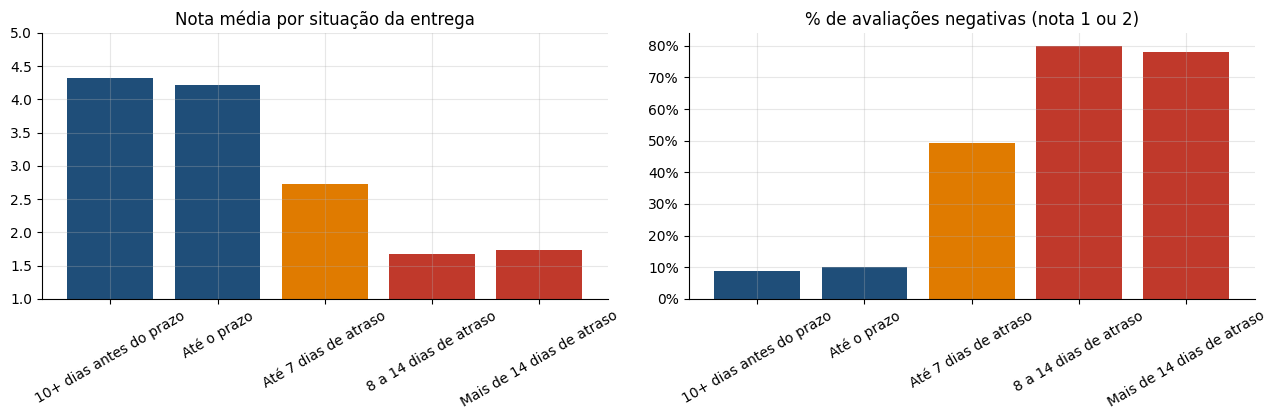

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
rotulos = entregas["situacao_entrega"].str[3:]
cores = [AZUL, AZUL, LARANJA, VERMELHO, VERMELHO]
axs[0].bar(rotulos, entregas["nota_media"], color=cores)
axs[0].set_title("Nota média por situação da entrega")
axs[0].set_ylim(1, 5)
axs[1].bar(rotulos, entregas["pct_notas_1_ou_2"], color=cores)
axs[1].set_title("% de avaliações negativas (nota 1 ou 2)")
axs[1].yaxis.set_major_formatter(mtick.PercentFormatter())
for ax in axs:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [17]:
# Atraso por estado do cliente: onde a logística falha mais?
consulta("""
SELECT
    c.customer_state AS uf,
    COUNT(*) AS pedidos,
    ROUND(AVG(julianday(p.order_delivered_customer_date) - julianday(p.order_purchase_timestamp)), 1) AS dias_medios_entrega,
    ROUND(100.0 * AVG(CASE WHEN date(p.order_delivered_customer_date) > date(p.order_estimated_delivery_date)
                           THEN 1.0 ELSE 0 END), 1) AS pct_atrasados
FROM pedidos AS p
JOIN clientes AS c ON c.customer_id = p.customer_id
WHERE p.order_status = 'delivered' AND p.order_delivered_customer_date IS NOT NULL
GROUP BY uf
HAVING COUNT(*) >= 300  -- Só estados com volume suficiente
ORDER BY pct_atrasados DESC
LIMIT 8
""")

,uf,pedidos,dias_medios_entrega,pct_atrasados
0,AL,397,24.50,21.40
1,MA,717,21.60,17.40
2,SE,335,21.50,15.20
3,PI,476,19.50,13.90
4,CE,1279,21.30,13.80
5,BA,3256,19.30,12.20
6,RJ,12350,15.30,12.10
7,PA,946,23.80,11.20


### Conclusões

- **93% dos pedidos chegam até o prazo** estimado, e 64% chegam com 10 dias ou mais de antecedência, o que sugere que **os prazos informados são conservadores**.
- **O atraso derruba a satisfação**: a nota média cai de **4,3** (entregas antecipadas) para **2,7** com até 7 dias de atraso e para **1,7** com mais de 7 dias. Nos atrasos de 8 dias ou mais, **cerca de 80% das avaliações são negativas** (nota 1 ou 2).
- **Alagoas é o estado com mais atrasos**: 21,4% dos pedidos, com 24,5 dias médios de entrega. Maranhão, Sergipe, Piauí e Ceará vêm em seguida: **o problema se concentra no Nordeste**.
- Recomendação: a logística é a maior alavanca de satisfação. Priorizar a melhoria das rotas do Nordeste e avisar proativamente o cliente sobre possíveis atrasos.

[Voltar ao Índice](#back)

## Etapa 8. Retenção: os clientes voltam a comprar? <a id='retention'></a>

**Pergunta:** que parcela dos clientes compra mais de uma vez?

Aqui o `customer_unique_id` é essencial, porque cada pedido tem um `customer_id` diferente. Em seguida, faço uma **análise de coorte**: agrupo os clientes pelo mês da primeira compra e acompanho quantos voltam a comprar nos meses seguintes.

In [18]:
consulta("""
WITH compras_cliente AS (
    SELECT c.customer_unique_id, COUNT(DISTINCT p.order_id) AS pedidos
    FROM pedidos AS p
    JOIN clientes AS c ON c.customer_id = p.customer_id
    WHERE p.order_status = 'delivered'
    GROUP BY c.customer_unique_id
)
SELECT
    CASE WHEN pedidos = 1 THEN '1 pedido' WHEN pedidos = 2 THEN '2 pedidos' ELSE '3 ou mais' END AS compras,
    COUNT(*) AS clientes,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS percentual
FROM compras_cliente
GROUP BY compras
ORDER BY compras
""")

,compras,clientes,percentual
0,1 pedido,90557,97.00
1,2 pedidos,2573,2.76
2,3 ou mais,228,0.24


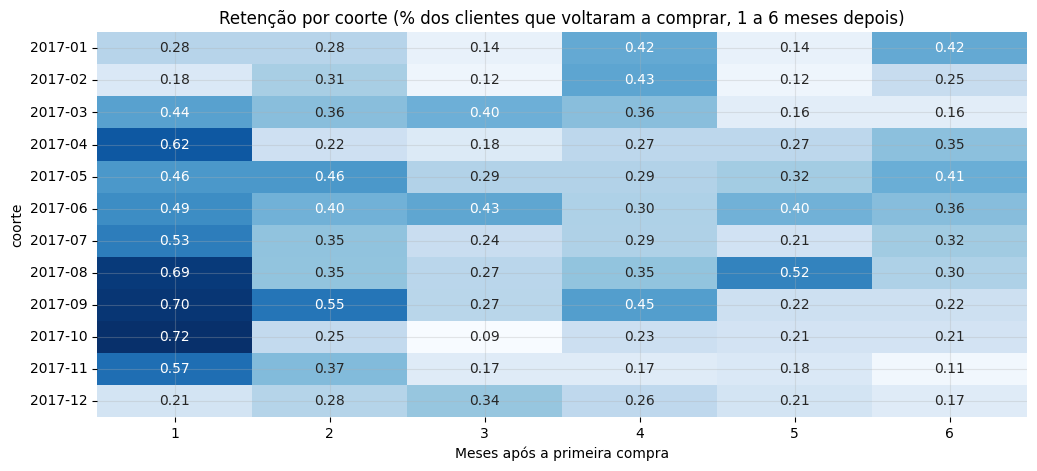

Retenção média no 1º mês: 0.49% | no 3º mês: 0.25%


In [19]:
coortes = consulta("""
WITH compras AS (
    -- Mês de cada compra de cada cliente
    SELECT DISTINCT c.customer_unique_id AS cliente, strftime('%Y-%m', p.order_purchase_timestamp) AS mes
    FROM pedidos AS p
    JOIN clientes AS c ON c.customer_id = p.customer_id
    WHERE p.order_status = 'delivered'
),
primeira_compra AS (
    -- A coorte do cliente é o mês da primeira compra
    SELECT cliente, MIN(mes) AS coorte FROM compras GROUP BY cliente
),
atividade AS (
    -- Quantos meses se passaram entre a primeira compra e cada compra
    SELECT
        f.coorte,
        c.cliente,
        (CAST(substr(c.mes, 1, 4) AS INTEGER) - CAST(substr(f.coorte, 1, 4) AS INTEGER)) * 12
          + CAST(substr(c.mes, 6, 2) AS INTEGER) - CAST(substr(f.coorte, 6, 2) AS INTEGER) AS mes_relativo
    FROM compras AS c
    JOIN primeira_compra AS f ON f.cliente = c.cliente
)
SELECT coorte, mes_relativo, COUNT(DISTINCT cliente) AS clientes
FROM atividade
WHERE coorte BETWEEN '2017-01' AND '2017-12'
GROUP BY coorte, mes_relativo
""")

# Monta a tabela de coortes: % de clientes de cada coorte que comprou de novo em cada mês
tabela = coortes.pivot(index="coorte", columns="mes_relativo", values="clientes").fillna(0)
retencao = tabela.div(tabela[0], axis=0) * 100
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(retencao.loc[:, 1:6], annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar=False)
ax.set_title("Retenção por coorte (% dos clientes que voltaram a comprar, 1 a 6 meses depois)")
ax.set_xlabel("Meses após a primeira compra")
plt.show()
print(f"Retenção média no 1º mês: {retencao[1].mean():.2f}% | no 3º mês: {retencao[3].mean():.2f}%")

### Conclusões

- **97% dos clientes compraram uma única vez**. Só 3% voltaram a comprar no período.
- Na análise de coorte, a retenção é de **menos de 0,5% no primeiro mês** e de cerca de 0,25% no terceiro mês, em todas as coortes de 2017.
- Esse é o **principal problema do negócio**: quase toda a receita depende de conquistar novos clientes, o que é caro. Mesmo uma melhora pequena na recompra teria grande impacto.
- Recomendação: criar ações de recompra, como e-mails pós-compra, cupons para a segunda compra e recomendações de produtos, e medir o efeito com testes A/B.

[Voltar ao Índice](#back)

## Etapa 9. Desempenho dos vendedores <a id='sellers'></a>

**Pergunta:** quem são os melhores vendedores de cada estado, e existem vendedores que vendem muito mas deixam os clientes insatisfeitos?

Uso `RANK() OVER (PARTITION BY ...)`, que cria um ranking **separado para cada estado**.

In [20]:
vendedores = consulta("""
WITH nota_pedido AS (
    SELECT order_id, AVG(review_score) AS nota FROM avaliacoes GROUP BY order_id
),
desempenho AS (
    SELECT
        i.seller_id,
        v.seller_state AS uf,
        COUNT(DISTINCT i.order_id) AS pedidos,
        SUM(i.price) AS receita,
        AVG(n.nota) AS nota_media,
        AVG(CASE WHEN date(p.order_delivered_customer_date) > date(p.order_estimated_delivery_date)
                 THEN 1.0 ELSE 0 END) AS taxa_atraso
    FROM itens AS i
    JOIN pedidos AS p    ON p.order_id = i.order_id
    JOIN vendedores AS v ON v.seller_id = i.seller_id
    LEFT JOIN nota_pedido AS n ON n.order_id = i.order_id
    WHERE p.order_status = 'delivered'
    GROUP BY i.seller_id, v.seller_state
)
SELECT
    uf,
    substr(seller_id, 1, 8) AS vendedor,  -- Abrevia o identificador
    pedidos,
    ROUND(receita, 2) AS receita,
    ROUND(nota_media, 2) AS nota_media,
    ROUND(100 * taxa_atraso, 1) AS pct_atraso,
    RANK() OVER (PARTITION BY uf ORDER BY receita DESC) AS ranking_no_estado
FROM desempenho
WHERE pedidos >= 30  -- Só vendedores com volume relevante
""")

# Os 3 maiores vendedores dos 3 estados com mais vendedores
vendedores[vendedores.uf.isin(["SP", "PR", "MG"]) & (vendedores.ranking_no_estado <= 3)].sort_values(["uf", "ranking_no_estado"])

,uf,vendedor,pedidos,receita,nota_media,pct_atraso,ranking_no_estado
18,MG,a1043baf,702,"99,309.23",4.25,4.90,1
19,MG,25c5c91f,156,"54,208.78",3.73,6.00,2
20,MG,7299e27e,335,"34,107.44",4.43,4.20,3
90,PR,ccc4bbb5,184,"72,926.72",4.32,6.30,1
91,PR,522620dc,172,"56,690.49",3.91,8.40,2
92,PR,77530e97,312,"45,676.60",4.08,8.90,3
222,SP,4869f7a5,1124,"226,987.93",4.14,10.50,1
223,SP,4a3ca931,1772,"196,882.12",3.83,9.70,2
224,SP,fa1c13f2,578,"190,917.14",4.37,9.20,3


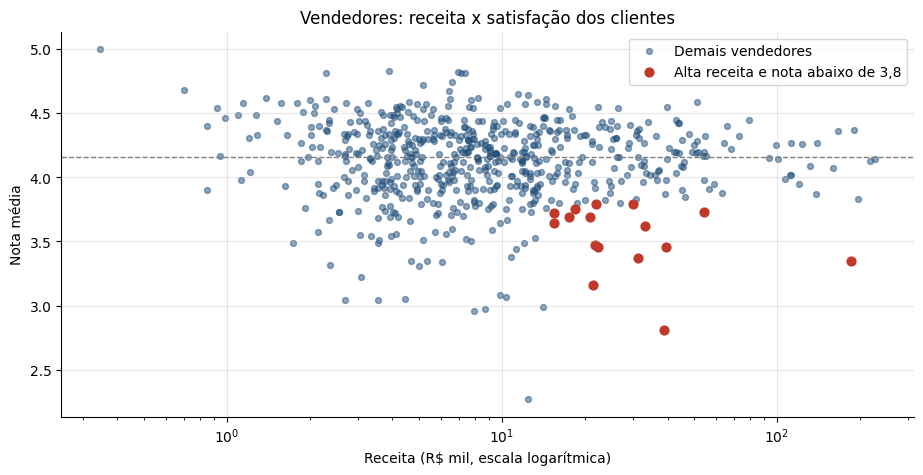

Vendedores analisados: 627
Vendedores em alerta: 16 | taxa média de atraso deles: 8.9% contra 6.4% dos demais


In [21]:
# Matriz de desempenho: receita x nota média, para vendedores com 30 ou mais pedidos
fig, ax = plt.subplots(figsize=(11, 5))
alerta = (vendedores.nota_media < 3.8) & (vendedores.receita > vendedores.receita.quantile(0.75))
ax.scatter(vendedores.loc[~alerta, "receita"] / 1000, vendedores.loc[~alerta, "nota_media"], s=18, alpha=0.5, color=AZUL, label="Demais vendedores")
ax.scatter(vendedores.loc[alerta, "receita"] / 1000, vendedores.loc[alerta, "nota_media"], s=40, color=VERMELHO,
           label="Alta receita e nota abaixo de 3,8")
ax.set_xscale("log")
ax.axhline(vendedores.nota_media.median(), color="gray", ls="--", lw=1)
ax.set_xlabel("Receita (R$ mil, escala logarítmica)")
ax.set_ylabel("Nota média")
ax.set_title("Vendedores: receita x satisfação dos clientes")
ax.legend()
plt.show()

print(f"Vendedores analisados: {len(vendedores)}")
print(f"Vendedores em alerta: {alerta.sum()} | taxa média de atraso deles: {vendedores.loc[alerta, 'pct_atraso'].mean():.1f}% "
      f"contra {vendedores.loc[~alerta, 'pct_atraso'].mean():.1f}% dos demais")

### Conclusões

- O ranking por estado identifica os vendedores mais importantes de cada região, uma informação útil para a gestão de contas.
- A matriz de receita e satisfação mostra **16 vendedores em alerta**: estão entre os 25% que mais faturam, mas têm nota média abaixo de 3,8. A taxa média de atraso deles é de **8,9%, contra 6,4%** dos demais.
- Recomendação: acompanhar esses vendedores de perto, com metas de prazo de envio, porque eles afetam a experiência de muitos clientes.

[Voltar ao Índice](#back)

## Etapa 10. Pagamentos e parcelamento <a id='payments'></a>

**Pergunta:** como os clientes pagam e o parcelamento está ligado ao valor da compra?

In [22]:
consulta("""
SELECT
    payment_type AS meio_de_pagamento,
    COUNT(DISTINCT order_id) AS pedidos,
    ROUND(100.0 * SUM(payment_value) / SUM(SUM(payment_value)) OVER (), 1) AS participacao_no_valor_pct,
    ROUND(AVG(payment_value), 2) AS valor_medio
FROM pagamentos
WHERE payment_type <> 'not_defined'
GROUP BY payment_type
ORDER BY participacao_no_valor_pct DESC
""")

,meio_de_pagamento,pedidos,participacao_no_valor_pct,valor_medio
0,credit_card,76505,78.30,163.32
1,boleto,19784,17.90,145.03
2,voucher,3866,2.40,65.70
3,debit_card,1528,1.40,142.57


In [23]:
parcelas = consulta("""
SELECT
    CASE
        WHEN payment_installments <= 1 THEN '1x'
        WHEN payment_installments <= 3 THEN '2x a 3x'
        WHEN payment_installments <= 6 THEN '4x a 6x'
        ELSE '7x ou mais'
    END AS parcelas,
    COUNT(*) AS pagamentos,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS percentual,
    ROUND(AVG(payment_value), 2) AS valor_medio
FROM pagamentos
WHERE payment_type = 'credit_card'
GROUP BY parcelas
ORDER BY MIN(payment_installments)
""")
parcelas

,parcelas,pagamentos,percentual,valor_medio
0,1x,25457,33.10,95.87
1,2x a 3x,22874,29.80,134.23
2,4x a 6x,16257,21.20,181.32
3,7x ou mais,12207,15.90,334.51


### Conclusões

- O **cartão de crédito domina**, com 78% do valor pago, seguido do **boleto**, com 18%.
- **Dois terços dos pagamentos com cartão são parcelados**, e o valor médio cresce com o número de parcelas: de R\$ 96 à vista para R\$ 335 em 7 vezes ou mais.
- O parcelamento é o que viabiliza as compras de maior valor. Oferecer mais parcelas sem juros em categorias de ticket alto pode aumentar a conversão.

[Voltar ao Índice](#back)

## Etapa 11. Segmentação RFM com SQL <a id='rfm'></a>

**Pergunta:** como dividir os clientes em grupos para direcionar ações de marketing?

A segmentação **RFM** classifica os clientes por:
- **R (Recência):** há quanto tempo foi a última compra
- **F (Frequência):** quantas compras o cliente fez
- **M (Valor monetário):** quanto o cliente gastou

Uso `NTILE(5)` para dar notas de 1 a 5 em recência e valor (5 = melhor). Como quase todos os clientes compraram uma única vez, a frequência é tratada de forma simples: **uma compra ou mais de uma**. A data de referência é o dia seguinte à última compra da base.

In [24]:
rfm = consulta("""
WITH base AS (
    SELECT
        c.customer_unique_id AS cliente,
        MAX(p.order_purchase_timestamp) AS ultima_compra,
        COUNT(DISTINCT p.order_id) AS frequencia,
        SUM(i.price + i.freight_value) AS valor
    FROM pedidos AS p
    JOIN clientes AS c ON c.customer_id = p.customer_id
    JOIN itens AS i    ON i.order_id = p.order_id
    WHERE p.order_status = 'delivered'
    GROUP BY c.customer_unique_id
),
notas AS (
    SELECT
        cliente, frequencia, valor,
        julianday((SELECT date(MAX(order_purchase_timestamp), '+1 day') FROM pedidos)) - julianday(ultima_compra) AS recencia_dias,
        NTILE(5) OVER (ORDER BY ultima_compra) AS nota_r,  -- 5 = comprou mais recentemente
        NTILE(5) OVER (ORDER BY valor) AS nota_m           -- 5 = gastou mais
    FROM base
),
segmentos AS (
    SELECT *,
        CASE
            WHEN frequencia >= 2 AND nota_r >= 4 THEN '1. Campeões'
            WHEN frequencia >= 2                 THEN '2. Fiéis em risco'
            WHEN nota_r >= 4 AND nota_m >= 4     THEN '3. Novos de alto valor'
            WHEN nota_r >= 4                     THEN '4. Novos'
            WHEN nota_m >= 4                     THEN '5. Alto valor em risco'
            ELSE                                      '6. Hibernando'
        END AS segmento
    FROM notas
)
SELECT
    segmento,
    COUNT(*) AS clientes,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_clientes,
    ROUND(100.0 * SUM(valor) / SUM(SUM(valor)) OVER (), 1) AS pct_receita,
    ROUND(AVG(recencia_dias), 0) AS recencia_media_dias,
    ROUND(AVG(valor), 2) AS valor_medio
FROM segmentos
GROUP BY segmento
ORDER BY segmento
""")
rfm

,segmento,clientes,pct_clientes,pct_receita,recencia_media_dias,valor_medio
0,1. Campeões,1203,1.30,2.50,138.00,322.53
1,2. Fiéis em risco,1598,1.70,3.10,368.00,297.99
2,3. Novos de alto valor,14413,15.40,28.20,140.00,302.10
3,4. Novos,21726,23.30,10.30,139.00,72.90
4,5. Alto valor em risco,20691,22.20,40.00,385.00,298.37
5,6. Hibernando,33727,36.10,15.80,386.00,72.46


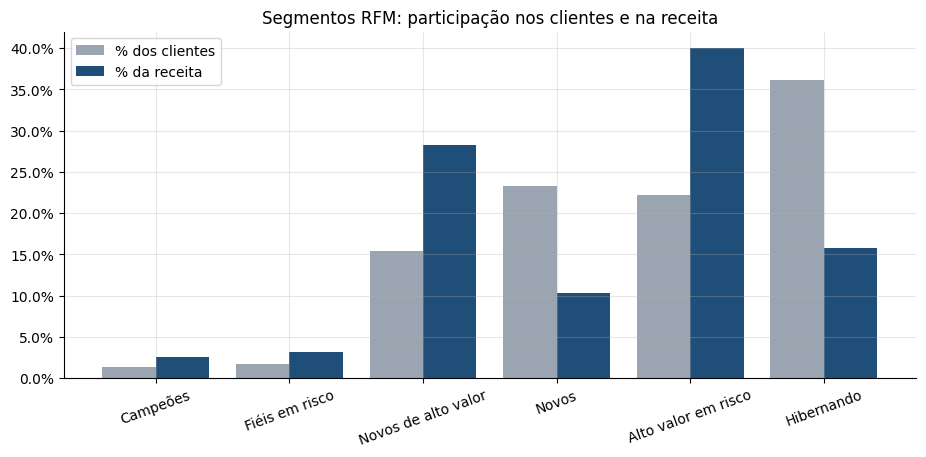

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = range(len(rfm))
ax.bar([i - 0.2 for i in x], rfm["pct_clientes"], 0.4, color=CINZA, label="% dos clientes")
ax.bar([i + 0.2 for i in x], rfm["pct_receita"], 0.4, color=AZUL, label="% da receita")
ax.set_xticks(list(x))
ax.set_xticklabels(rfm["segmento"].str[3:], rotation=20)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Segmentos RFM: participação nos clientes e na receita")
ax.legend()
plt.show()

### Conclusões

| Segmento | O que significa | Ação recomendada |
|---|---|---|
| **Campeões** (1,3%) | Compraram mais de uma vez e recentemente | Programa de fidelidade e acesso antecipado a ofertas |
| **Fiéis em risco** (1,7%) | Compraram mais de uma vez, mas há muito tempo | Campanha de reativação personalizada |
| **Novos de alto valor** (15,4%) | Primeira compra recente e de alto valor: **28% da receita** | Prioridade máxima para a segunda compra |
| **Novos** (23,3%) | Primeira compra recente e de baixo valor | Cupom de segunda compra e recomendações |
| **Alto valor em risco** (22,2%) | Gastaram muito, mas há mais de um ano: **40% da receita** | Reativação com ofertas nas categorias que compraram |
| **Hibernando** (36,1%) | Baixo valor e sem compras há muito tempo | Ações de baixo custo, como e-mail automático |

Os segmentos **Novos de alto valor** e **Alto valor em risco** somam 37% dos clientes e **68% da receita**: são o foco principal das ações de retenção.

[Voltar ao Índice](#back)

## Conclusão geral <a id='end'></a>

Neste projeto, analisei cerca de 100 mil pedidos da Olist com **SQL**, usando JOINs entre 8 tabelas, CTEs, funções de janela (`LAG`, `RANK`, `NTILE`, `SUM OVER`) e CASE, para responder às principais perguntas de um e-commerce.

**Principais resultados:**

- **Tamanho do negócio:** R\$ 15,4 milhões em 96 mil pedidos entregues, com ticket médio de R\$ 160. A receita cresceu 143% de 2017 para 2018 (janeiro a agosto), mas se estabilizou ao longo de 2018.
- **Categorias:** 18 das 74 categorias concentram 80% da receita.
- **Frete:** pesa até o dobro no Norte e no Nordeste em relação ao Sudeste.
- **Logística e satisfação:** entregas com mais de 7 dias de atraso derrubam a nota média para menos de 2, e cerca de 80% dessas avaliações são negativas. **Alagoas** é o estado com mais atrasos (21%).
- **Retenção:** **97% dos clientes compram uma única vez**, o principal problema do negócio.
- **Segmentação RFM:** dois segmentos somam 37% dos clientes e 68% da receita.

**Recomendações para o negócio:**

1. **Retenção é a prioridade:** ações de segunda compra para os novos clientes de alto valor e reativação dos clientes de alto valor em risco, sempre medidas com testes A/B.
2. **Logística no Nordeste:** atacar os atrasos, que derrubam a satisfação e ameaçam a recompra.
3. **Frete regional:** parcerias logísticas ou vendedores locais para crescer fora do Sudeste.
4. **Gestão de vendedores:** acompanhar de perto os 16 vendedores com alta receita e nota baixa.

**Próximos passos:** a segmentação RFM feita aqui com regras de negócio pode ser aprofundada com **clustering**, o tema de um próximo projeto.

[Voltar ao Índice](#back)